# 03 · Calibration

Calibration = choose the parameters so that the model reproduces the bench.
Mechanically that is an optimisation problem. The part that needs engineering
judgement is everything around it: what to compare, which optimiser fits the
problem, whether the answer is unique, how uncertain it is, and whether a good
fit means the parameters are right. This notebook goes through all of these on
data set A (reality has the same structure as the model), then repeats the
exercise on data set B, where reality contains effects the model does not have.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy.optimize import least_squares, minimize, differential_evolution
from scipy.stats import qmc

import driveline as dl
import plotstyle
C = plotstyle.use()
np.set_printoptions(precision=3, suppress=True)

bench = dl.load_bench("A")
D = dl.N_PAR
ln0, lnL, lnU = np.log(dl.NOMINAL), np.log(dl.LOWER), np.log(dl.UPPER)


def plot_orders(curves, bench, title=None):
    fig, axes = plt.subplots(2, len(dl.ORDERS), figsize=(15, 5.2), sharex=True)
    for ch in range(2):
        for o, n in enumerate(dl.ORDERS):
            a = axes[ch, o]
            a.plot(bench["rpm"], bench["amp"][ch, o], ".", color=plotstyle.MUTED, ms=3,
                   label="bench" if (ch, o) == (0, 0) else None)
            for label, amp, st in curves:
                a.plot(dl.RPM, amp[ch, o], label=label if (ch, o) == (0, 0) else None, **st)
            a.set_yscale("log")
            if ch == 0:
                a.set_title(f"order {n:g}")
            if o == 0:
                a.set_ylabel(f"{dl.CHANNELS[ch]} speed ampl. [rad/s]")
            if ch == 1:
                a.set_xlabel("rpm")
    fig.legend(loc="outside upper right", ncol=4)
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    return fig, axes

## 1 · The problem, stated properly

We look for

$$\hat{\boldsymbol\theta} = \arg\min_{\boldsymbol\theta}\ \sum_i r_i(\boldsymbol\theta)^2,\qquad r_i = \ln y_i^{\text{model}}(\boldsymbol\theta) - \ln y_i^{\text{bench}}$$

**Why squares?** If each measurement equals the true value times independent
log-normal scatter with standard deviation $\sigma$, the probability of observing
the data given $\boldsymbol\theta$ is $\propto \exp\!\big(-\sum r_i^2 / 2\sigma^2\big)$. Minimising the
sum of squares is then *maximum likelihood* estimation. So the innocent-looking
cost function is a statement about the noise: independent, same relative size
everywhere, no outliers. When that is wrong (and with a wrong model structure it
always is), the estimate is still usable but its error bars are not – see section 6.

**Three practical rules** carried over from notebooks 01 and 02:

* optimise in $\ln\theta$ (all parameters positive, comparable scale, bounds become a box),
* keep bounds – they encode what is physically plausible,
* hand the optimiser the **residual vector**, not just the scalar cost.

## 2 · Nonlinear least squares

A general optimiser sees one number per run. A least-squares solver
(Gauss–Newton / Levenberg–Marquardt / trust-region) sees all 810 residuals and
their sensitivities $\mathbf{S} = \partial\mathbf{r}/\partial\ln\boldsymbol\theta$ – the same matrix as in notebook 02.
It linearises, $\mathbf{r}(\boldsymbol\theta+\Delta) \approx \mathbf{r} + \mathbf{S}\Delta$, solves the *linear*
least-squares problem for the step $\Delta$, and repeats. Because the linearisation
is usually very good near the solution, it converges in a handful of iterations.
Each iteration costs one run plus D runs for the finite-difference Jacobian.

In [2]:
class Counter:
    """Wraps a function, counts calls and records the best cost seen so far."""
    def __init__(self, f, to_cost):
        self.f, self.to_cost, self.hist = f, to_cost, []

    def __call__(self, x):
        out = self.f(x)
        c = self.to_cost(out)
        self.hist.append(c if not self.hist else min(c, self.hist[-1]))
        return out


rms = lambda r: float(np.sqrt(np.mean(np.square(r))))
res_fun = Counter(lambda lnx: dl.residuals(np.exp(lnx), bench), rms)

t0 = time.perf_counter()
sol = least_squares(res_fun, ln0, bounds=(lnL, lnU))
x_hat = np.exp(sol.x)
print(f"{len(res_fun.hist)} model runs, {time.perf_counter() - t0:.2f} s,"
      f"  cost {rms(dl.residuals(dl.NOMINAL, bench)):.3f} → {rms(sol.fun):.4f}")
print(f"\n{'':10s} {'nominal':>10s} {'calibrated':>11s} {'multiplier':>11s}")
for n, a, b in zip(dl.NAMES, dl.NOMINAL, x_hat):
    print(f"{n:10s} {a:10.4g} {b:11.4g} {b / a:11.3f}")

81 model runs, 0.05 s,  cost 0.312 → 0.0406

              nominal  calibrated  multiplier
k_prim          6e+04   7.402e+04       1.234
k_damper         1600        1315       0.822
k_shaft          9000   1.036e+04       1.151
k_cush            220       287.5       1.307
c_damper         0.25      0.4637       1.855
c_cush           0.25      0.1898       0.759
J_gbx           0.004    0.004494       1.124
gas_scale           1      0.9392       0.939


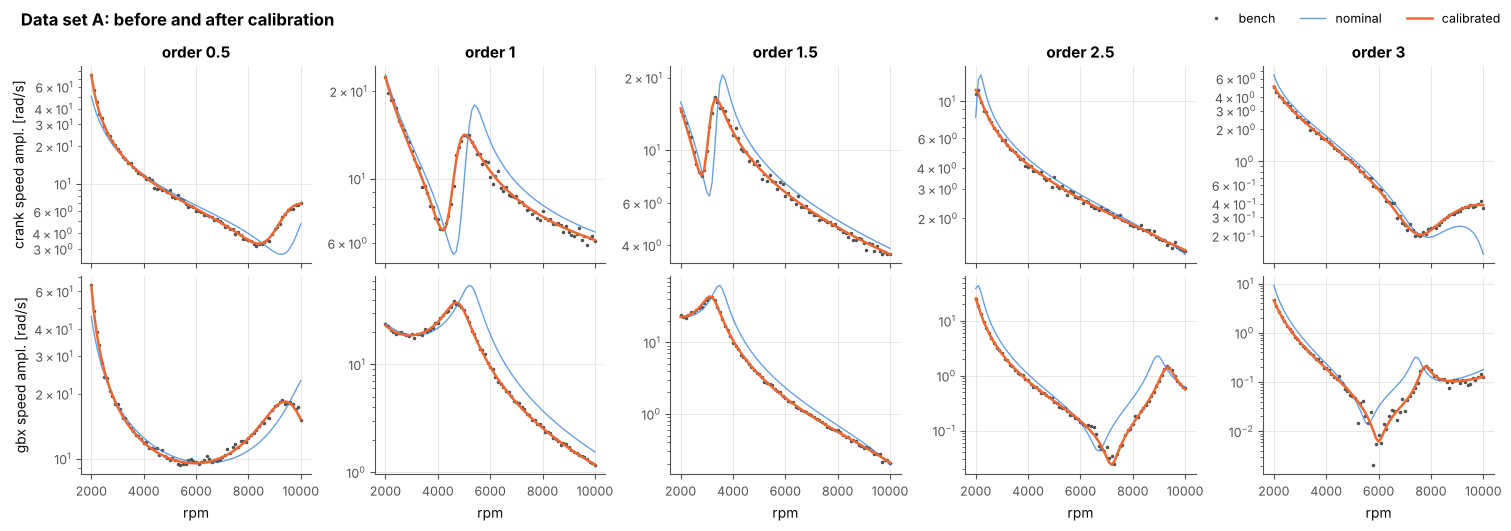

In [3]:
plot_orders([("nominal", dl.simulate(dl.NOMINAL), dict(color=C[0], lw=1.0, alpha=0.7)),
             ("calibrated", dl.simulate(x_hat), dict(color=C[1]))], bench,
            title="Data set A: before and after calibration")
plt.show()

The final cost of about 0.04 means a typical deviation of 4 % – the level of the
measurement scatter. The fit cannot and should not get better than the noise.

## 3 · Does the choice of optimiser matter?

Same problem, same start, but now optimisers that only get the scalar cost:

* **Nelder–Mead** – derivative-free simplex; robust, slow, scales badly with D.
* **Powell** – derivative-free line searches along directions.
* **L-BFGS-B** – quasi-Newton with finite-difference gradients (D+1 runs per gradient).
* **Differential evolution** – population-based global search; no start point
  needed, but thousands of runs.

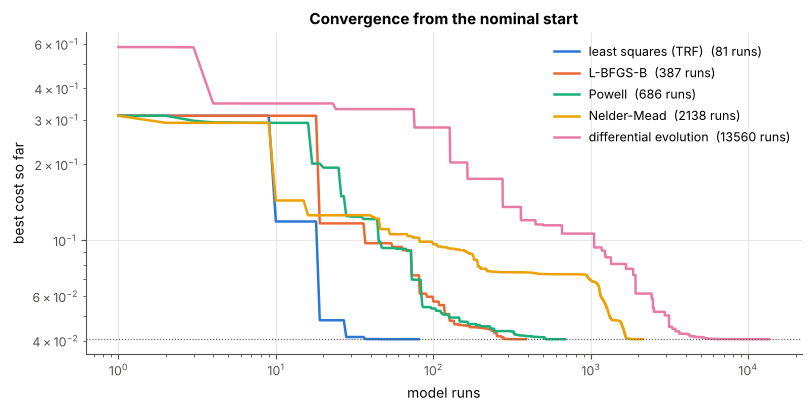

In [4]:
bounds = list(zip(lnL, lnU))
runs = {"least squares (TRF)": res_fun.hist}
for method in ("L-BFGS-B", "Powell", "Nelder-Mead"):
    f = Counter(lambda lnx: dl.cost(np.exp(np.clip(lnx, lnL, lnU)), bench), float)
    minimize(f, ln0, method=method, bounds=bounds, options=dict(maxiter=20000))
    runs[method] = f.hist
f = Counter(lambda lnx: dl.cost(np.exp(lnx), bench), float)
differential_evolution(f, bounds, seed=0, maxiter=150, tol=1e-6, polish=False)
runs["differential evolution"] = f.hist

fig, ax = plt.subplots(figsize=(8, 4))
for (label, h), c in zip(runs.items(), C):
    ax.loglog(np.arange(1, len(h) + 1), h, color=c, label=f"{label}  ({len(h)} runs)")
ax.axhline(rms(sol.fun), color=plotstyle.MUTED, lw=0.8, ls=":")
ax.set(xlabel="model runs", ylabel="best cost so far", title="Convergence from the nominal start")
ax.legend()
plt.show()

All of them arrive at the same minimum, but the number of runs differs by
orders of magnitude. With a 1 ms model nobody cares. With a model that takes a
minute per run-up it is the difference between an hour and a half and more than
nine days. **Whenever your misfit is a sum of squares of many residuals, use a
least-squares solver.** Scalar optimisers are for when you only *have* a scalar
(a lap time, a peak value) – and that is also where surrogate-based methods earn
their keep (notebook 04).

## 4 · Is the minimum unique? Multi-start

Least squares is a *local* method: it rolls downhill from the start point.
Resonance matching is a classic source of local minima – the optimiser can
line a model peak up with the wrong measured peak and get stuck. The cheap test:
start from many points spread over the bounds (a Sobol sample, notebook 01) and
see where each one ends.

32 fits in 2.1 s
final costs: [0.041 0.041 0.041 0.041 0.041 0.041 0.041 0.041 0.041 0.041 0.041 0.041
 0.041 0.041 0.041 0.041 0.041 0.041 0.041 0.041 0.041 0.041 0.041 0.041
 0.041 0.041 0.041 0.041 0.041 0.041 0.041 0.408]


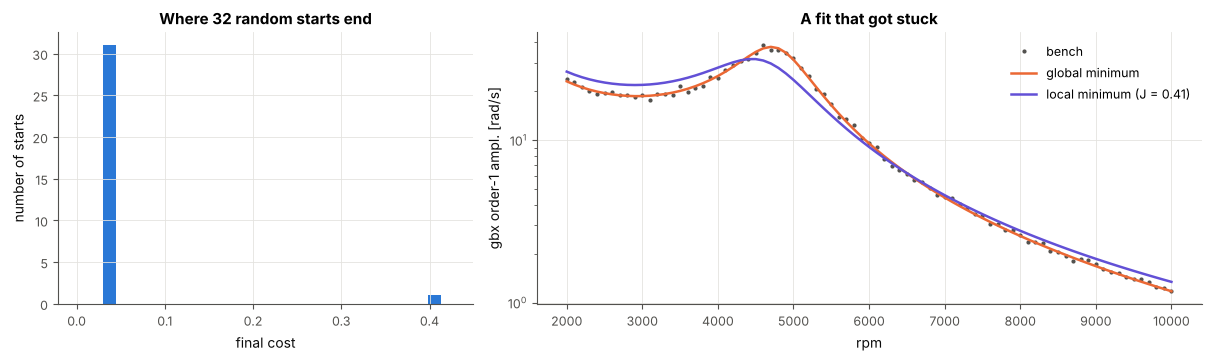

local minimum, multipliers: [0.54 0.61 1.56 1.2  1.21 2.01 0.7  1.08]


In [5]:
starts = lnL + qmc.Sobol(d=D, seed=5).random(32) * (lnU - lnL)
t0 = time.perf_counter()
sols = [least_squares(lambda l: dl.residuals(np.exp(l), bench), s, bounds=(lnL, lnU)) for s in starts]
finals = np.array([rms(s.fun) for s in sols])
print(f"32 fits in {time.perf_counter() - t0:.1f} s")
print("final costs:", np.sort(finals).round(4))

worst = sols[finals.argmax()]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), width_ratios=[1, 1.6])
ax[0].hist(finals, bins=np.linspace(0, finals.max() * 1.05, 30), color=C[0])
ax[0].set(xlabel="final cost", ylabel="number of starts", title="Where 32 random starts end")
i1 = list(dl.ORDERS).index(1.0)
ax[1].semilogy(dl.RPM, bench["amp"][1, i1], ".", color=plotstyle.MUTED, ms=4, label="bench")
ax[1].semilogy(dl.RPM, dl.simulate(x_hat)[1, i1], color=C[1], label="global minimum")
ax[1].semilogy(dl.RPM, dl.simulate(np.exp(worst.x))[1, i1], color=C[6], label=f"local minimum (J = {finals.max():.2f})")
ax[1].set(xlabel="rpm", ylabel="gbx order-1 ampl. [rad/s]", title="A fit that got stuck")
ax[1].legend()
plt.show()
print("local minimum, multipliers:", (np.exp(worst.x) / dl.NOMINAL).round(2))

Almost all starts reach the same point, which is strong evidence that it is the
global minimum. One start ends in a much worse local minimum with several
parameters on their bounds. Two lessons: (1) **a single fit is never proof** –
always run a multi-start; (2) *parameters sitting on bounds* and a *cost well
above the noise level* are the warning signs of a stuck fit.

## 5 · How certain are the calibrated values?

### 5.1 Linearised covariance

At the optimum the solver already holds the Jacobian $\mathbf{S}$. As in notebook 02,

$$\operatorname{Cov}(\ln\hat{\boldsymbol\theta}) \approx s^2 (\mathbf{S}^\top\mathbf{S})^{-1},\qquad s^2 = \frac{\sum r_i^2}{n - D}$$

The only difference: the noise level $s$ is now *estimated from the residuals*
instead of assumed. Standard deviations in $\ln\theta$ are relative errors, so
"0.01" reads as "1 %".

In [6]:
def covariance(sol):
    n, d = sol.jac.shape
    s2 = np.sum(sol.fun ** 2) / (n - d)
    return s2 * np.linalg.inv(sol.jac.T @ sol.jac), np.sqrt(s2)


cov, s_noise = covariance(sol)
std = np.sqrt(np.diag(cov))
print(f"estimated noise level s = {s_noise:.3f}  (the data were generated with 3 % scatter plus a floor)")

import make_bench_data as truth      # <- now we are allowed to look
x_true = truth.X_TRUE
print(f"\n{'':10s} {'estimate':>9s} {'± 1σ [%]':>9s} {'truth':>9s} {'error [%]':>10s} {'error/σ':>8s}")
for n, xh, sd, xt in zip(dl.NAMES, x_hat / dl.NOMINAL, std, x_true / dl.NOMINAL):
    print(f"{n:10s} {xh:9.3f} {100 * sd:9.2f} {xt:9.3f} {100 * (xh / xt - 1):10.2f} {np.log(xh / xt) / sd:8.2f}")

estimated noise level s = 0.041  (the data were generated with 3 % scatter plus a floor)

            estimate  ± 1σ [%]     truth  error [%]  error/σ
k_prim         1.234      0.83     1.250      -1.31    -1.58
k_damper       0.822      0.34     0.820       0.22     0.66
k_shaft        1.151      0.19     1.150       0.05     0.26
k_cush         1.307      0.70     1.300       0.54     0.77
c_damper       1.855      1.55     1.900      -2.39    -1.56
c_cush         0.759      4.27     0.700       8.45     1.90
J_gbx          1.124      0.54     1.120       0.32     0.60
gas_scale      0.939      0.15     0.940      -0.08    -0.55


The table is the pay-off of the whole exercise:

* Every parameter is recovered, most to better than 1 %; the errors are of the
  size the covariance predicts (|error/σ| mostly below 2).
* `c_cush` is the least certain, as notebook 02 forecast, and it is the
  one that is furthest off.

The covariance matrix also describes *joint* uncertainty. For the two damping
parameters:

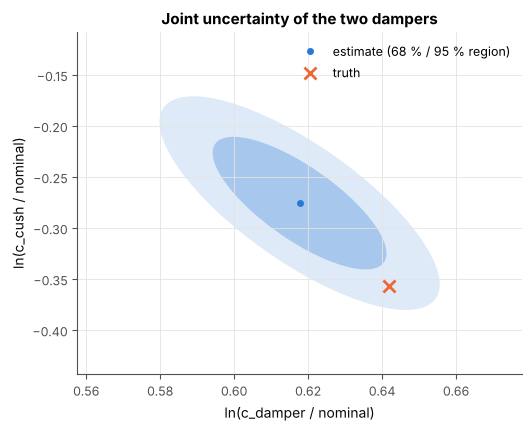

correlation: -0.76


In [7]:
def ellipse(ax, mean, cov2, n_std, **kw):
    w, v = np.linalg.eigh(cov2)
    ang = np.degrees(np.arctan2(v[1, 1], v[0, 1]))
    ax.add_patch(Ellipse(mean, 2 * n_std * np.sqrt(w[1]), 2 * n_std * np.sqrt(w[0]), angle=ang, **kw))


ia, ib = dl.NAMES.index("c_damper"), dl.NAMES.index("c_cush")
fig, ax = plt.subplots(figsize=(5.2, 4.2))
sub = cov[np.ix_([ia, ib], [ia, ib])]
for k, alpha in ((2.45, 0.15), (1.52, 0.3)):          # 95 % and 68 % regions for 2 parameters
    ellipse(ax, sol.x[[ia, ib]] - ln0[[ia, ib]], sub, k, color=C[0], alpha=alpha, lw=0)
ax.plot(*(sol.x[[ia, ib]] - ln0[[ia, ib]]), "o", color=C[0], label="estimate (68 % / 95 % region)")
ax.plot(*(np.log(x_true)[[ia, ib]] - ln0[[ia, ib]]), "x", color=C[1], ms=9, mew=2, label="truth")
ax.set(xlabel="ln(c_damper / nominal)", ylabel="ln(c_cush / nominal)",
       title="Joint uncertainty of the two dampers")
ax.legend(loc="upper right")
ax.autoscale()
ax.margins(0.3)
plt.show()
print(f"correlation: {sub[0, 1] / np.sqrt(sub[0, 0] * sub[1, 1]):.2f}")

The tilted ellipse is the valley: more clutch damping with less cush damping
fits almost as well. The truth lies inside the 95 % region, off along the valley
direction, exactly as expected.

### 5.2 Profile likelihood – a check that does not rely on linearisation

The covariance formula assumes the model is linear in the parameters over the
uncertainty range. A sturdier (and more expensive) check: fix one parameter at a
series of values, **re-optimise all others** each time and record how much worse
the best achievable fit gets. The parameter range where the sum of squares rises
by less than $3.84\,s^2$ is a 95 % confidence interval. Flat profiles expose
unidentifiable parameters even when the covariance formula produces nonsense.

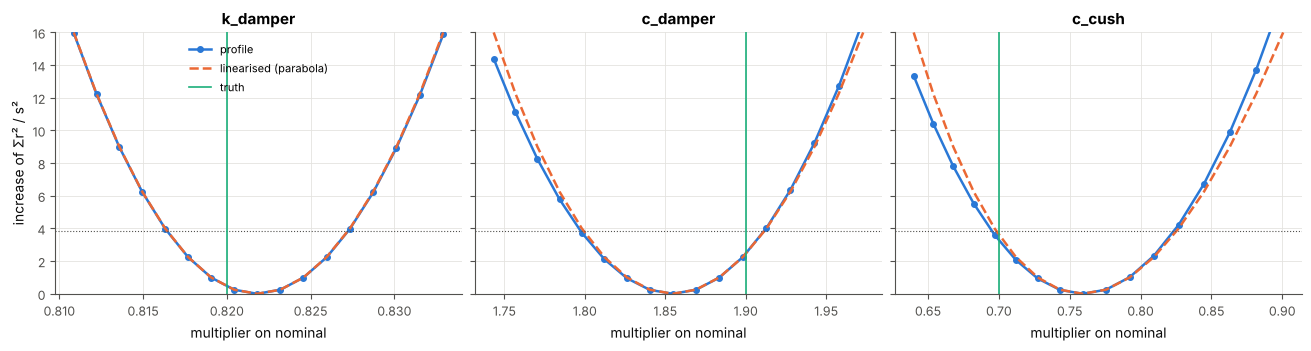

In [8]:
def fit_subset(bench, free, x_fixed, start=None, prior_sd=None, **kw):
    """Least squares over the parameters listed in `free`; others stay at x_fixed."""
    free = np.asarray(free)

    def res(l):
        x = np.array(x_fixed, float)
        x[free] = np.exp(l)
        r = dl.residuals(x, bench, **kw)
        if prior_sd is not None:                       # used in section 5.3
            r = np.concatenate([r, (l - ln0[free]) / prior_sd[free]])
        return r

    l0 = np.log(np.asarray(x_fixed if start is None else start)[free])
    return least_squares(res, np.clip(l0, lnL[free] + 1e-9, lnU[free] - 1e-9), bounds=(lnL[free], lnU[free]))


ssr0 = np.sum(sol.fun ** 2)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for a, name in zip(axes, ("k_damper", "c_damper", "c_cush")):
    j = dl.NAMES.index(name)
    grid = np.exp(sol.x[j] + np.linspace(-4, 4, 17) * std[j])
    prof = []
    for v in grid:
        x_fix = x_hat.copy(); x_fix[j] = v
        s_ = fit_subset(bench, [k for k in range(D) if k != j], x_fix)
        prof.append((np.sum(s_.fun ** 2) - ssr0) / s_noise ** 2)
    a.plot(grid / dl.NOMINAL[j], prof, "o-", label="profile")
    a.plot(grid / dl.NOMINAL[j], (np.log(grid) - sol.x[j]) ** 2 / std[j] ** 2, color=C[1], ls="--",
           label="linearised (parabola)")
    a.axhline(3.84, color=plotstyle.MUTED, lw=0.8, ls=":")
    a.axvline(x_true[j] / dl.NOMINAL[j], color=C[2], lw=1.2, label="truth")
    a.set(title=name, xlabel="multiplier on nominal", ylim=(0, 16))
axes[0].set_ylabel("increase of Σr² / s²")
axes[0].legend(fontsize=8)
plt.show()

Profile and parabola agree, so the linearised error bars can be trusted here.
When they disagree – asymmetric profiles, plateaus – trust the profile.

### 5.3 When the data are not enough: priors

Suppose the gearbox encoder had failed and the run was stopped at 6000 rpm.
Only the crank channel up to 6000 rpm is available.

In [9]:
mask = np.zeros((2, len(dl.ORDERS), len(dl.RPM)), bool)
mask[0][:, dl.RPM <= 6000] = True
mask = mask.ravel()
prior_sd = np.array([0.3, 0.3, 0.3, 0.3, 0.8, 0.8, 0.15, 0.1])     # how well we believe the nominal values (ln units)


def res_reduced(l, use_prior):
    r = dl.residuals(np.exp(l), bench)[mask] / s_noise             # in units of the noise
    return np.concatenate([r, (l - ln0) / prior_sd]) if use_prior else r


red = {lab: least_squares(res_reduced, ln0, bounds=(lnL, lnU), args=(flag,))
       for lab, flag in (("data only", False), ("data + prior", True))}
print(f"{'':10s} {'truth':>8s} {'data only':>10s} {'± [%]':>8s} {'data+prior':>11s} {'± [%]':>8s}")
sd = {lab: np.sqrt(np.diag(np.linalg.inv(s_.jac.T @ s_.jac))) for lab, s_ in red.items()}
for j, n in enumerate(dl.NAMES):
    print(f"{n:10s} {x_true[j] / dl.NOMINAL[j]:8.3f} {np.exp(red['data only'].x[j] - ln0[j]):10.3f} "
          f"{min(100 * sd['data only'][j], 9999):8.1f} {np.exp(red['data + prior'].x[j] - ln0[j]):11.3f} "
          f"{100 * sd['data + prior'][j]:8.1f}")

              truth  data only    ± [%]  data+prior    ± [%]
k_prim        1.250      1.398     24.2       1.260     16.9
k_damper      0.820      0.820    128.4       0.827      1.9
k_shaft       1.150      1.724   9343.5       1.024     29.9
k_cush        1.300      1.303    139.5       1.313      1.5
c_damper      1.900      1.820    173.2       1.869      7.6
c_cush        0.700      0.815     21.0       0.789     19.3
J_gbx         1.120      1.121    140.5       1.129      2.8
gas_scale     0.940      0.936      1.2       0.938      0.5


With the reduced data several parameters are essentially undetermined – the
error bar of `k_shaft` is thousands of percent, and its "estimate" is arbitrary.
The remedy is to say what you already know. A **prior** "the nominal value is
right to within ±30 %" is added as one extra residual per parameter,

$$r_{\text{prior},j} = \frac{\ln\theta_j - \ln\theta_{j,\text{nom}}}{\sigma_{\text{prior},j}},$$

with the data residuals divided by the noise level so that both are in the same
units. This is Tikhonov regularisation, and in Bayesian terms the result is the
*maximum a-posteriori* estimate. Its effect is selective: parameters the data
determine well ignore the prior; parameters the data cannot see stay near
nominal with the prior's uncertainty, instead of drifting to arbitrary values.

The alternative is to **fix** unidentifiable parameters at nominal – simpler,
but it pretends they are known exactly and understates the uncertainty of
everything correlated with them.

## 6 · Validation

A calibration is only worth something if it predicts data it has not seen. We
kept a second run-up at 50 % load aside.

validation run-up at 50 % load:
  nominal    J = 0.300
  calibrated J = 0.046   (calibration data: 0.041)


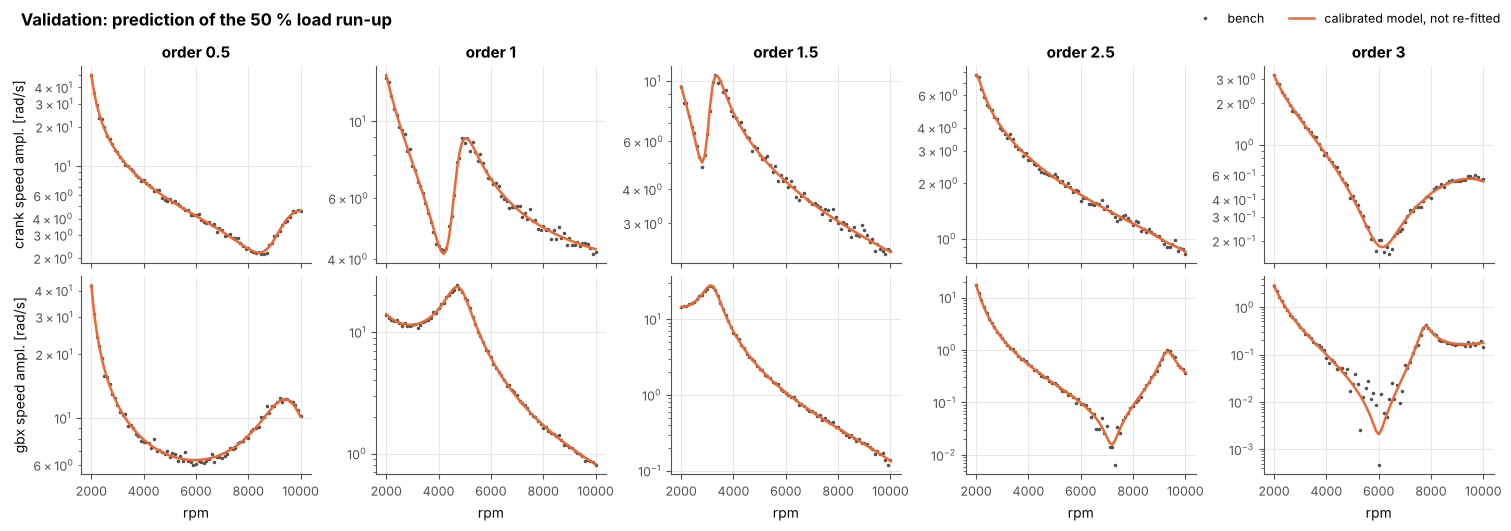

In [10]:
val = dl.load_bench("A_val")
amp_val = dl.simulate(x_hat, load=float(val["load"]))
print(f"validation run-up at {100 * float(val['load']):.0f} % load:")
print(f"  nominal    J = {dl.cost(dl.NOMINAL, val):.3f}")
print(f"  calibrated J = {dl.cost(x_hat, val):.3f}   (calibration data: {rms(sol.fun):.3f})")
plot_orders([("calibrated model, not re-fitted", amp_val, dict(color=C[1]))], val,
            title="Validation: prediction of the 50 % load run-up")
plt.show()

The error on the unseen run is as small as on the calibration run. Prefer
validation data that differ in a *physically meaningful* way (other load, other
gear, other temperature) over a random hold-out of points from the same run:
neighbouring rpm points are nearly copies of each other and would flatter any model.

## 7 · The real world: data set B

Data set B comes from a "bench" whose physics the model does not fully contain.
We don't know that yet – we just calibrate as before.

best of 16 starts: cost 0.192   (noise level would be ≈ 0.04)
validation (50 % load): nominal 0.363 → calibrated 0.181

            estimate  ± 1σ [%]     truth  error [%]  error/σ
k_prim         2.000     12.91     1.250       60.0      3.6  ← on bound
k_damper       0.715      1.51     0.820      -12.8     -9.1
k_shaft        1.032      0.86     1.150      -10.3    -12.6
k_cush         1.289      3.44     1.300       -0.8     -0.2
c_damper       1.908      7.47     1.900        0.4      0.1
c_cush         0.200     86.84     0.700      -71.4     -1.4  ← on bound
J_gbx          0.896      2.15     1.120      -20.0    -10.4
gas_scale      0.923      0.70     0.940       -1.8     -2.7


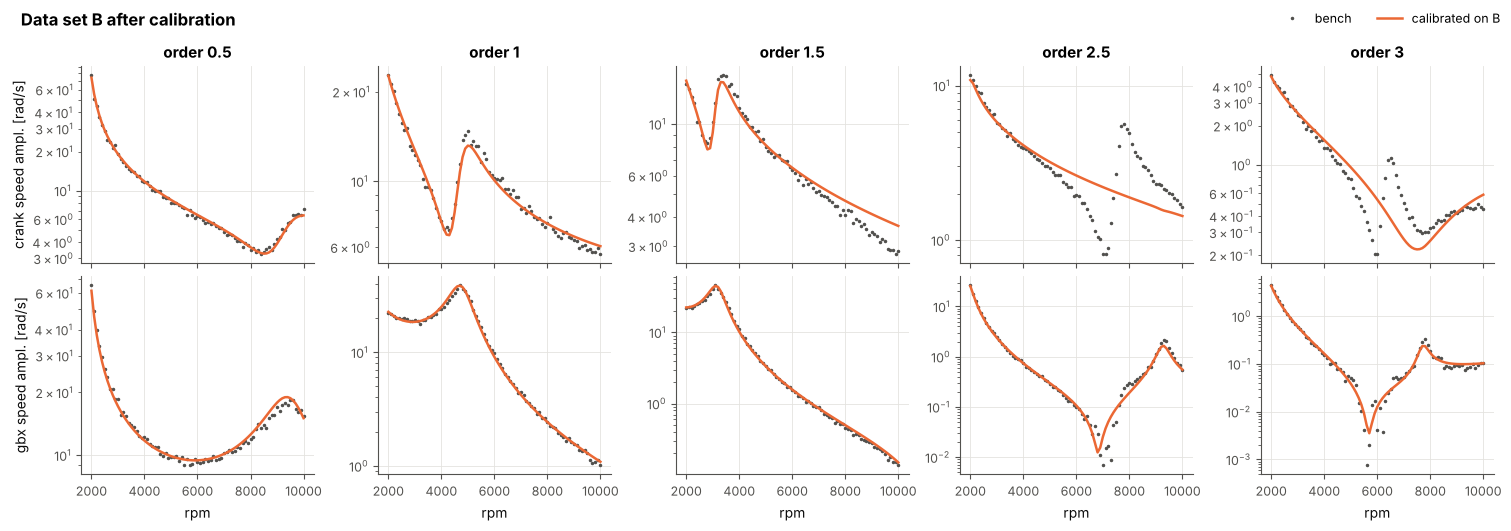

In [11]:
bench_B, val_B = dl.load_bench("B"), dl.load_bench("B_val")
starts = lnL + qmc.Sobol(d=D, seed=7).random(16) * (lnU - lnL)
starts[0] = ln0
sols_B = [least_squares(lambda l: dl.residuals(np.exp(l), bench_B), s, bounds=(lnL, lnU)) for s in starts]
sol_B = min(sols_B, key=lambda s: s.cost)
xB = np.exp(sol_B.x)
covB, sB = covariance(sol_B)
print(f"best of {len(sols_B)} starts: cost {rms(sol_B.fun):.3f}   (noise level would be ≈ 0.04)")
print(f"validation (50 % load): nominal {dl.cost(dl.NOMINAL, val_B):.3f} → calibrated {dl.cost(xB, val_B):.3f}")
print(f"\n{'':10s} {'estimate':>9s} {'± 1σ [%]':>9s} {'truth':>9s} {'error [%]':>10s} {'error/σ':>8s}")
for j, n in enumerate(dl.NAMES):
    xh, xt, sdj = xB[j] / dl.NOMINAL[j], x_true[j] / dl.NOMINAL[j], np.sqrt(covB[j, j])
    flag = "  ← on bound" if min(abs(sol_B.x[j] - lnL[j]), abs(sol_B.x[j] - lnU[j])) < 1e-3 else ""
    print(f"{n:10s} {xh:9.3f} {100 * sdj:9.2f} {xt:9.3f} {100 * (xh / xt - 1):10.1f} {np.log(xh / xt) / sdj:8.1f}{flag}")

plot_orders([("calibrated on B", dl.simulate(xB), dict(color=C[1]))], bench_B,
            title="Data set B after calibration")
plt.show()

Read this result carefully, because this is what real calibrations look like:

* The cost improves a lot and **the validation run improves too**. By the usual
  criteria the calibration "worked".
* Yet several parameters are **wrong by 10–20 %, many standard deviations away
  from the truth**, and two sit on their bounds. The optimiser has bent the
  parameters to compensate for physics the model lacks. The error bars are
  meaningless because their assumption (model = reality + white noise) is violated.
* The final cost is far above the noise level. That gap is the signature of
  **structural model error**.

A good fit therefore does not prove that the parameters are physically right.
If you use them only to reproduce this bench, fine. If you carry them into
another model, or into a design decision ("the clutch damper stiffness is
evidently 1150 Nm/rad"), you are in trouble.

### 7.1 Residual analysis: ask the residuals what is missing

With a correct model the residuals are patternless noise. Structure in the
residuals – runs of the same sign, bumps at specific speeds – is the fingerprint
of the missing physics.

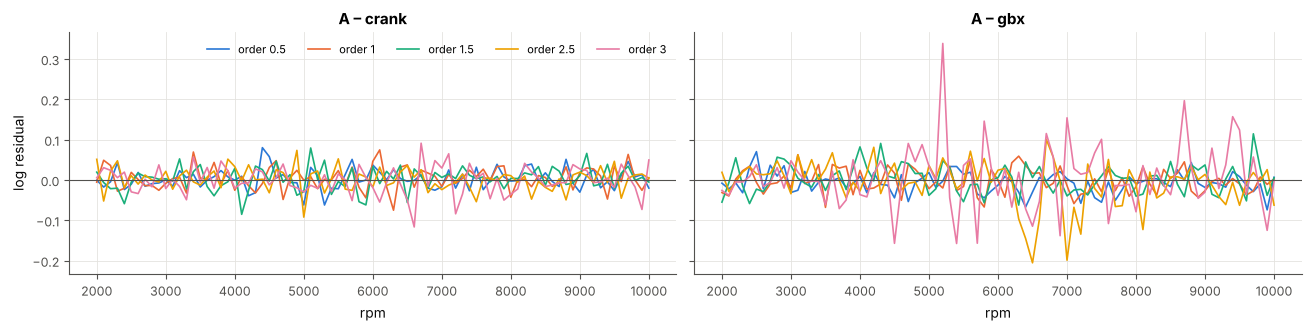

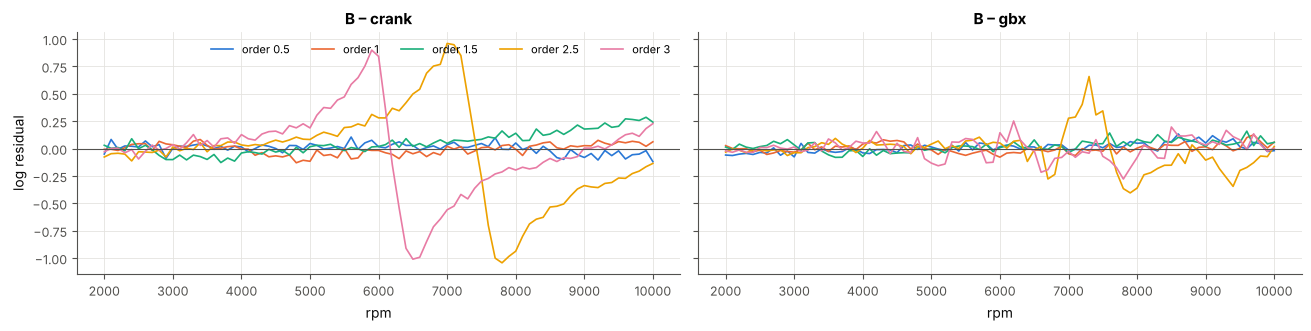

mean lag-1 autocorrelation of the residuals:  A -0.02   B 0.68


In [12]:
def residual_plot(x, bench, title, **kw):
    r = dl.residuals(x, bench, **kw).reshape(2, len(dl.ORDERS), -1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), sharey=True)
    for ch, a in enumerate(axes):
        for o, n in enumerate(dl.ORDERS):
            a.plot(dl.RPM, r[ch, o], color=C[o], lw=1.2, label=f"order {n:g}")
        a.axhline(0, color=plotstyle.MUTED, lw=0.8)
        a.set(title=f"{title} – {dl.CHANNELS[ch]}", xlabel="rpm")
    axes[0].set_ylabel("log residual")
    axes[0].legend(ncol=5, fontsize=8)
    lag1 = np.mean([np.corrcoef(r[c, o, :-1], r[c, o, 1:])[0, 1] for c in range(2) for o in range(len(dl.ORDERS))])
    return fig, lag1


_, lagA = residual_plot(x_hat, bench, "A")
plt.show()
_, lagB = residual_plot(xB, bench_B, "B")
plt.show()
print(f"mean lag-1 autocorrelation of the residuals:  A {lagA:.2f}   B {lagB:.2f}")

For A the residuals are white (autocorrelation ≈ 0). For B they are strongly
correlated from one rpm point to the next, with large sign-changing swings at the
crank: order 3 around 6200 rpm and order 2.5 around 7400 rpm. Both correspond to
about 310 Hz. Two orders misbehaving at the *same frequency* point to **an
unmodelled resonance** – something attached to the crank with its own natural
frequency.

### 7.2 Fix the model, not the parameters

In this example the missing pieces are (a) an alternator rotor on a flexible
stub shaft and (b) a clutch damper whose damping is hysteretic (friction-like,
complex stiffness $k(1+i\eta)$) rather than viscous. `dl.simulate` can switch both
on through its `structure` argument. We add three parameters (`eta` of the
damper, stiffness and loss factor of the alternator shaft), drop the now unused
`c_damper`, and calibrate again. The alternator stiffness needs a multi-start,
because a resonance can be matched to the wrong bump.

final cost per start: [0.04, 0.04, 0.04, 0.206]
cost 0.040,  validation 0.047

            model as is  improved model    truth
k_prim            2.000           1.255    1.250
k_damper          0.715           0.824    0.820
k_shaft           1.032           1.156    1.150
k_cush            1.289           1.308    1.300
c_damper          1.908               –    1.900
c_cush            0.200           0.683    0.700
J_gbx             0.896           1.135    1.120
gas_scale         0.923           0.942    0.940
damper_eta            –          0.1833   0.1817
k_alt                 –       1.401e+04  1.4e+04
eta_alt               –         0.06129     0.06


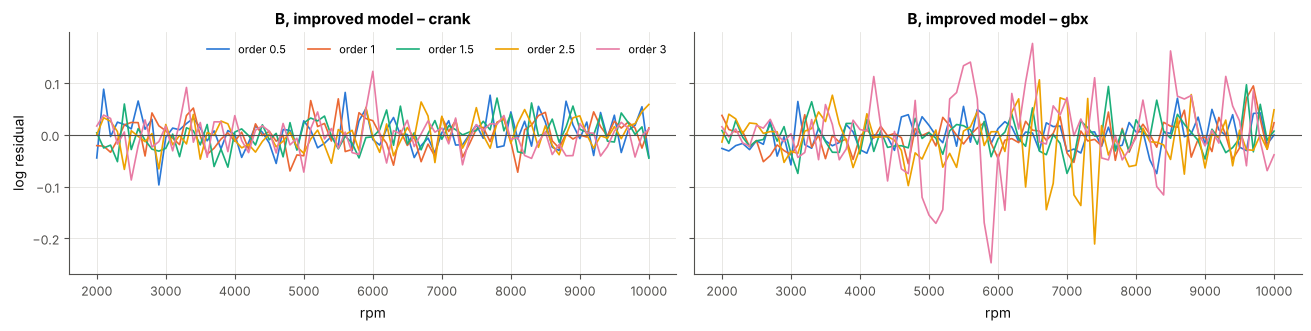

lag-1 autocorrelation: 0.00


In [13]:
free = [j for j, n in enumerate(dl.NAMES) if n != "c_damper"]
extra_names = ["damper_eta", "k_alt", "eta_alt"]
lb2 = np.concatenate([lnL[free], np.log([0.02, 3e3, 0.01])])
ub2 = np.concatenate([lnU[free], np.log([1.00, 5e4, 0.30])])


def unpack(l):
    x = dl.NOMINAL.copy()
    x[free] = np.exp(l[:len(free)])
    return x, dict(damper_eta=np.exp(l[-3]), J_alt=4.0e-3, k_alt=np.exp(l[-2]), eta_alt=np.exp(l[-1]))


def res_B2(l, b=bench_B):
    x, st = unpack(l)
    return dl.residuals(x, b, structure=st)


cands = [least_squares(res_B2, np.concatenate([ln0[free], np.log([0.15, k0, 0.05])]), bounds=(lb2, ub2))
         for k0 in (5e3, 1e4, 2e4, 4e4)]
print("final cost per start:", [round(rms(c.fun), 3) for c in cands])
sol_B2 = min(cands, key=lambda s: s.cost)
xB2, stB2 = unpack(sol_B2.x)
print(f"cost {rms(sol_B2.fun):.3f},  validation {rms(res_B2(sol_B2.x, val_B)):.3f}\n")
print(f"{'':10s} {'model as is':>12s} {'improved model':>15s} {'truth':>8s}")
for j, n in enumerate(dl.NAMES):
    b2 = f"{xB2[j] / dl.NOMINAL[j]:15.3f}" if j in free else f"{'–':>15s}"
    print(f"{n:10s} {xB[j] / dl.NOMINAL[j]:12.3f} {b2} {x_true[j] / dl.NOMINAL[j]:8.3f}")
for n in extra_names:
    print(f"{n:10s} {'–':>12s} {stB2[n]:15.4g} {truth.STRUCT_B[n]:8.4g}")

_, lagB2 = residual_plot(xB2, bench_B, "B, improved model", structure=stB2)
plt.show()
print(f"lag-1 autocorrelation: {lagB2:.2f}")

With the right structure the cost drops to the noise level, the residuals turn
white and all shared parameters land on their true values. This is the ideal
outcome and the order of preference in practice:

1. **Improve the physics** when the residuals tell you what is missing and the
   effect is modellable. Parameters keep their meaning; the model extrapolates.
2. **Restrict the claim**: calibrate only on data the model can represent (mask
   the affected orders/speeds) and state the validity range.
3. **Model the discrepancy empirically**: keep the physics model and learn the
   remaining systematic residual with a flexible data-driven model (Gaussian
   process or neural network). That makes predictions better *inside the tested
   range* but does not repair the parameters. Notebook 06 does this.

## 8 · Summary – a calibration checklist

1. Define residuals that reflect what matters and how the noise behaves (log amplitudes here).
2. Sensitivity analysis first: fix or put priors on what the data cannot see.
3. Optimise in log-parameters with bounds, using a least-squares solver on the residual vector.
4. Multi-start. Check for parameters on bounds.
5. Compare the final cost with the expected noise level.
6. Look at the residuals: white = fine; structured = missing physics.
7. Quantify uncertainty (covariance, profile likelihood) – and only believe it if step 6 passed.
8. Validate on a run that differs physically from the calibration run.

The calibrated parameters are saved for the following notebooks.

In [14]:
np.savez("data/calibration.npz", names=dl.NAMES, x_A=x_hat, cov_A=cov, x_B=xB, x_true=x_true,
         x_B2=xB2, struct_B2=np.array([stB2[n] for n in extra_names]))
print("saved data/calibration.npz")

saved data/calibration.npz


### Try it yourself

1. Calibrate on A with **linear** residuals (`np` difference of amplitudes instead
   of logs). Which parameters get worse, and why?
2. Calibrate on the 50 % load run and validate on the full-load run. Calibrate on
   both at once (concatenate the residual vectors). How do the error bars change?
3. On data set B, mask orders 2.5 and 3 at the crank and calibrate the original
   model on the rest (option 2 above). How close do the parameters get?
4. Replace the Gaussian assumption by a robust loss: `least_squares(..., loss="soft_l1", f_scale=0.1)`.
   Does it help on B?
5. For full Bayesian uncertainty, sample the posterior with MCMC
   ([emcee](https://emcee.readthedocs.io)) using `-0.5*sum(r**2)/s**2` as log-likelihood,
   and compare the sample cloud with the covariance ellipse of section 5.1.

Next: **04 – Surrogate models.**